# JAX/NumPyro transit-parameter refinement after NEMESIS II

This notebook **calls the supplied NEMESIS II model**, `refine_transit_parameters`,
from `examples/reference_wrappers/nemesis_jaxoplanet_refit.py`. It is the same
function called by the supplied `run_jaxoplanet_batch.py` disBatch worker.
The actual modeling implementation is provided unchanged alongside the tutorial;
it is **not** part of the installed `nemesis_tess` package.

The refit consumes NEMESIS `*_final_LC.csv` and `*_TLS_bestfit.csv`, uses a
quadratically limb-darkened `jaxoplanet` `TransitOrbit`, integrates over TESS
exposure time, initializes the fit, and samples a NumPyro NUTS posterior.
This demonstration uses the TIC 103633434 / Sector 20 data saved by notebook 01.

**Scientific settings:** The production batch worker uses 4 chains, 2000 warmup,
3000 samples, a Student-t likelihood (`nu=4`), `ld_mode="gaussian"`, density
prior, and `target_accept=0.95`. The shorter demonstration below is for
interface/testing only, **not publication-quality inference**.

In [1]:
import os
from pathlib import Path
import sys

# Run in a fresh kernel before importing JAX or NumPyro.
for name in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS',
             'NUMEXPR_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
    os.environ[name] = '1'

# Make the exact reference wrapper importable from a repository checkout.
wrapper_dirs = [p / 'examples' / 'reference_wrappers'
                for p in (Path.cwd(), *Path.cwd().parents)]
wrapper_dir = next((p for p in wrapper_dirs
                    if (p / 'nemesis_jaxoplanet_refit.py').is_file()), None)
if wrapper_dir is None:
    raise FileNotFoundError(
        'Cannot locate examples/reference_wrappers/nemesis_jaxoplanet_refit.py. '
        'Open the notebook in a clone of the NEMESIS repository.')
sys.path.insert(0, str(wrapper_dir.resolve()))

import numpyro
numpyro.set_platform('cpu')
numpyro.set_host_device_count(2)  # two chains for this demonstration
import jax
from nemesis_jaxoplanet_refit import refine_transit_parameters

print('Using refit module:', wrapper_dir / 'nemesis_jaxoplanet_refit.py')
print('JAX devices:', jax.devices())

/Users/daxfeliz/.venv_pkg_test/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using refit module: /Users/daxfeliz/Desktop/TESS/NEMESIS_II/NEMESIS_repo/examples/reference_wrappers/nemesis_jaxoplanet_refit.py
JAX devices: [CpuDevice(id=0), CpuDevice(id=1)]


In [3]:
import pandas as pd

TIC_ID, SECTOR = 103633434, 20
root = Path.home() / 'nemesis_tutorials' / 'toi1235_s20'
base = root / f'Sector_{SECTOR:04d}'
lc_path = (base / 'NEMESIS_FFI_LCs' /
           f'TIC_{TIC_ID}_Sector_{SECTOR:04d}_final_LC.csv')
bestfit_path = (base / 'NEMESIS_FFI_TLS_Report' /
                f'TIC_{TIC_ID}_Sector_{SECTOR:04d}_TLS_bestfit.csv')

for path in (lc_path, bestfit_path):
    if not path.is_file():
        raise FileNotFoundError(f'Missing {path}; complete notebook 01 first.')

bestfit = pd.read_csv(bestfit_path)
print('Best-fit has', len(bestfit.columns), 'columns')
print('Limb-darkening columns present:', [c for c in
      ('qld_a', 'qld_b', 'LEOVetter_transit_u1', 'LEOVetter_transit_u2')
      if c in bestfit.columns])
# The wrapper finds limb-darkening coefficients in this table if u_fixed=None;
# without usable values, supply explicit u_fixed=(u1, u2) instead.

Best-fit has 200 columns
Limb-darkening columns present: ['LEOVetter_transit_u1', 'LEOVetter_transit_u2']


In [6]:
outdir = root / 'jaxoplanet'
outdir.mkdir(parents=True, exist_ok=True)
save_name = f'TIC_{TIC_ID}_Sector_{SECTOR:04d}'

# A *short* two-chain demonstrator: NOT a scientific posterior.
summary, idata = refine_transit_parameters(
    lightcurve=str(lc_path),
    bestfit=str(bestfit_path),
    outdir=str(outdir),
    save_name=save_name,
    method='TLS',
    u_fixed=None,
    ld_mode='gaussian',
    prior_style='paper1',
    r_hi_sigmas=10.0,
    rho_star_prior=True,
    rho_frac_err=0.15,
    likelihood='student_t',
    student_t_nu=4.0,
    n_chains=2,
    n_warmup=400,
    n_samples=800,
    target_accept=0.95,
    make_plots=True,
    make_timeseries=True,
    make_trace=True,
    make_corner=True,
    save_idata=False,
    show_plots=False,
    verbose=True,
)

assert len(summary) == 1
assert str(summary['MCMC likelihood'].iloc[0]).lower() == 'student_t'
posterior_csv = outdir / f'{save_name}_jaxoplanet_posterior.csv'
assert posterior_csv.is_file(), f'Wrapper did not write {posterior_csv}'
print('Posterior CSV:', posterior_csv)
for col in ('MCMC Period [d]', 'MCMC T0 [BTJD]', 'MCMC Dur [hrs]',
            'MCMC rhat max', 'MCMC ess bulk min', 'MCMC n divergences',
            'MCMC r ceiling frac', 'MCMC converged'):
    print(col, summary[col].iloc[0] if col in summary else 'not recorded')

  [prior] u = (0.2946, 0.3316) from LEOVetter_transit_u1/u2; Kipping q = (0.3921, 0.2352)
  [prep] 1183 -> 982 finite/quality -> 208 in window; texp=29.97 min, supersample=7
  [prior] rho/rho_sun = 2.4508 from M_star / R_star**3; file repaired = True
  [prior] rho_star = 3.455 +/- 0.518 g/cm^3 from rho_sun * (M_star / R_star**3); sigma_ln = 0.1398; implied a/Rs = 12.95
  [map ] AutoDelta + Adam, 3000 steps
  [map ] final Evidence Lower Bound (ELBO) loss -1341.5922


Running chain 0: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 1200/1200 [13:11<00:00,  1.52it/s]

Running chain 1: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 1200/1200 [13:23<00:00,  1.49it/s]


  [diag] r_hat max 1.0400, ess_bulk min 40, ess_tail min 56, divergences 0, converged False


/Users/daxfeliz/Desktop/TESS/NEMESIS_II/NEMESIS_repo/examples/reference_wrappers/nemesis_jaxoplanet_refit.py:1086: RuntimeWarning: Convergence gate not met for TIC_103633434_Sector_0020: r_hat_max=1.0400 (<=1.01), ess_bulk_min=40 (>=400), divergences=0 (==0). Do not publish these intervals without re-running with more warmup or a higher target_accept.
  warnings.warn(


  [prior] Rp/Rs ceiling r_hi=0.03823; 0.00 percent of draws within 2 percent of it
  [shrink] t0=0.98  period=0.97  duration=0.75  r=0.92  b=0.62  f0=0.99  log_jitter=0.85   NOTE: rho_star_prior is ON, so b shrinkage measures the density prior, not the light curve
  [save] /Users/daxfeliz/nemesis_tutorials/toi1235_s20/jaxoplanet/TIC_103633434_Sector_0020_jaxoplanet_posterior.csv
  [save] /Users/daxfeliz/nemesis_tutorials/toi1235_s20/jaxoplanet/TIC_103633434_Sector_0020_jaxoplanet_fit.png
  [save] /Users/daxfeliz/nemesis_tutorials/toi1235_s20/jaxoplanet/TIC_103633434_Sector_0020_jaxoplanet_timeseries.png
  [save] /Users/daxfeliz/nemesis_tutorials/toi1235_s20/jaxoplanet/TIC_103633434_Sector_0020_jaxoplanet_trace.png
  [save] /Users/daxfeliz/nemesis_tutorials/toi1235_s20/jaxoplanet/TIC_103633434_Sector_0020_jaxoplanet_corner.png
Posterior CSV: /Users/daxfeliz/nemesis_tutorials/toi1235_s20/jaxoplanet/TIC_103633434_Sector_0020_jaxoplanet_posterior.csv
MCMC Period [d] 3.4451916195219887
MCMC

## Convergence and passing results to TRICERATOPS

The wrapper writes the single-row `*_jaxoplanet_posterior.csv` itself and
returns `(summary, idata)`. Do not confuse a successful function return with
a converged fit. Inspect **R-hat**, bulk/tail ESS, divergences, prior-edge
occupancy (`MCMC r ceiling frac`), and `MCMC converged` before using the
posterior ephemeris for science.

For production, run the same wrapper with the real NEMESIS II batch-worker
settings (`n_chains=4`, `n_warmup=2000`, `n_samples=3000`) and inspect the
result before promoting it into notebook 03. The TRICERATOPS bridge then uses
posterior **period, epoch and duration**, but retains the **search-measured
depth** from the same detrended light curve instead of geometric `(Rp/Rs)^2`.

### Phase-folded transit fit and residuals

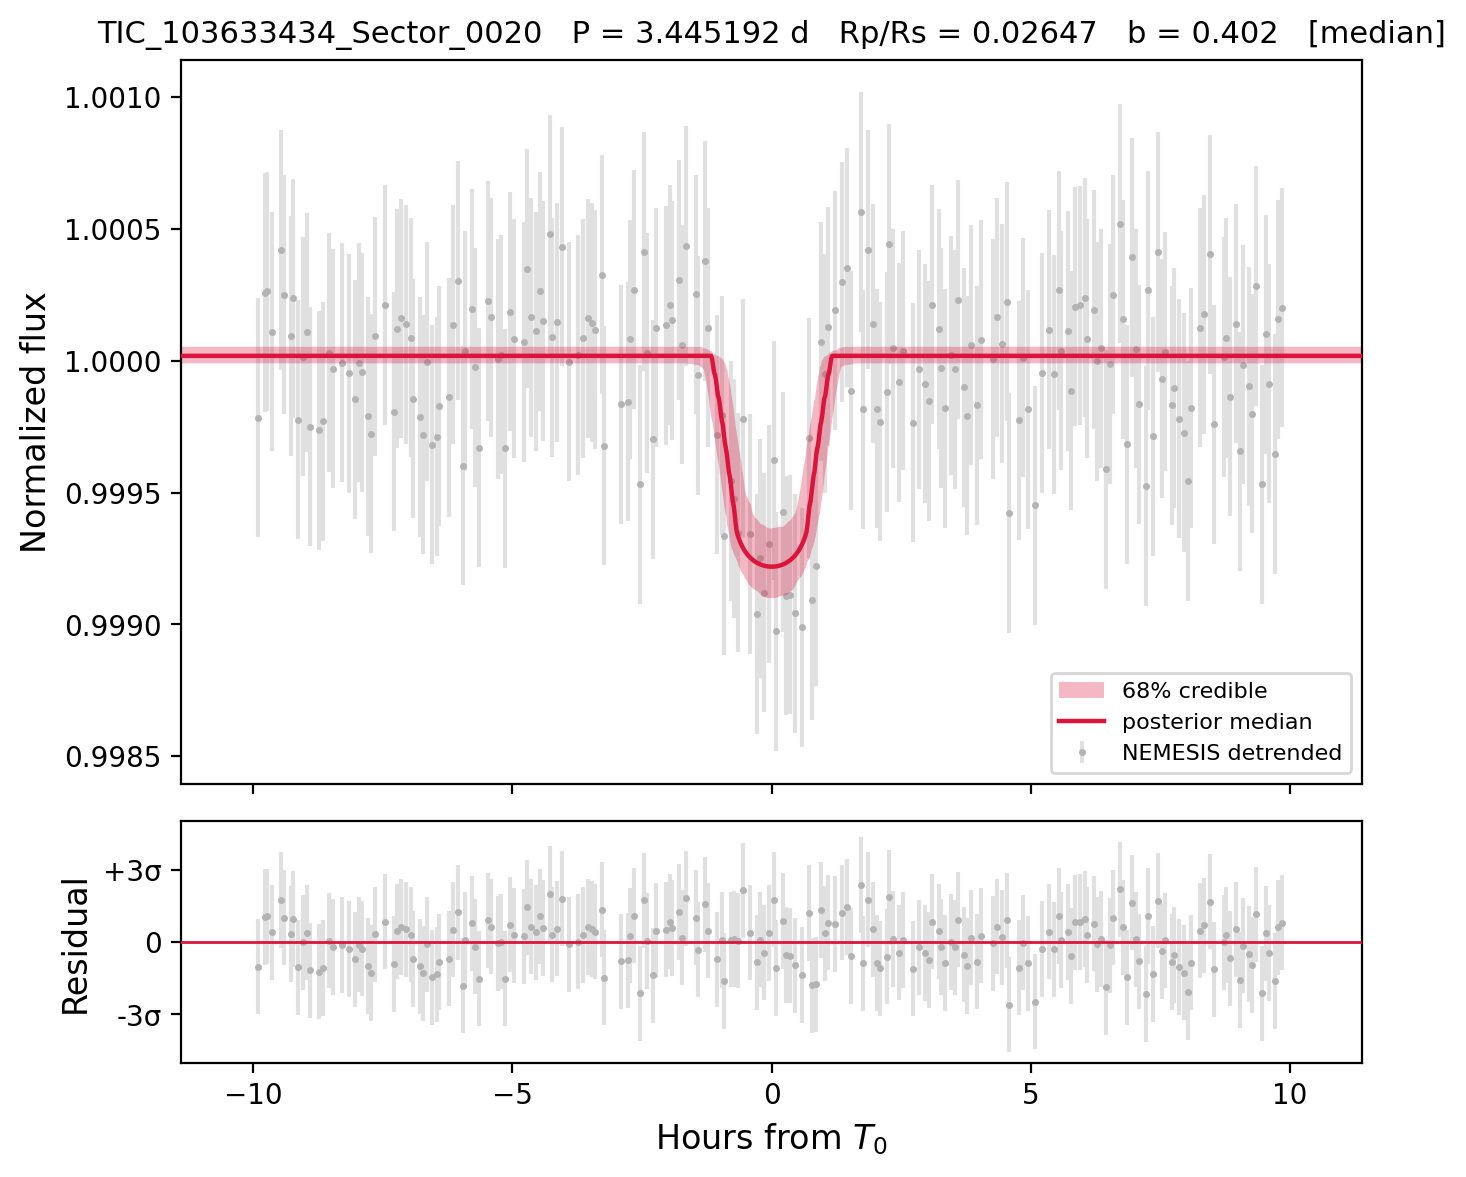

### Time-series model and residuals

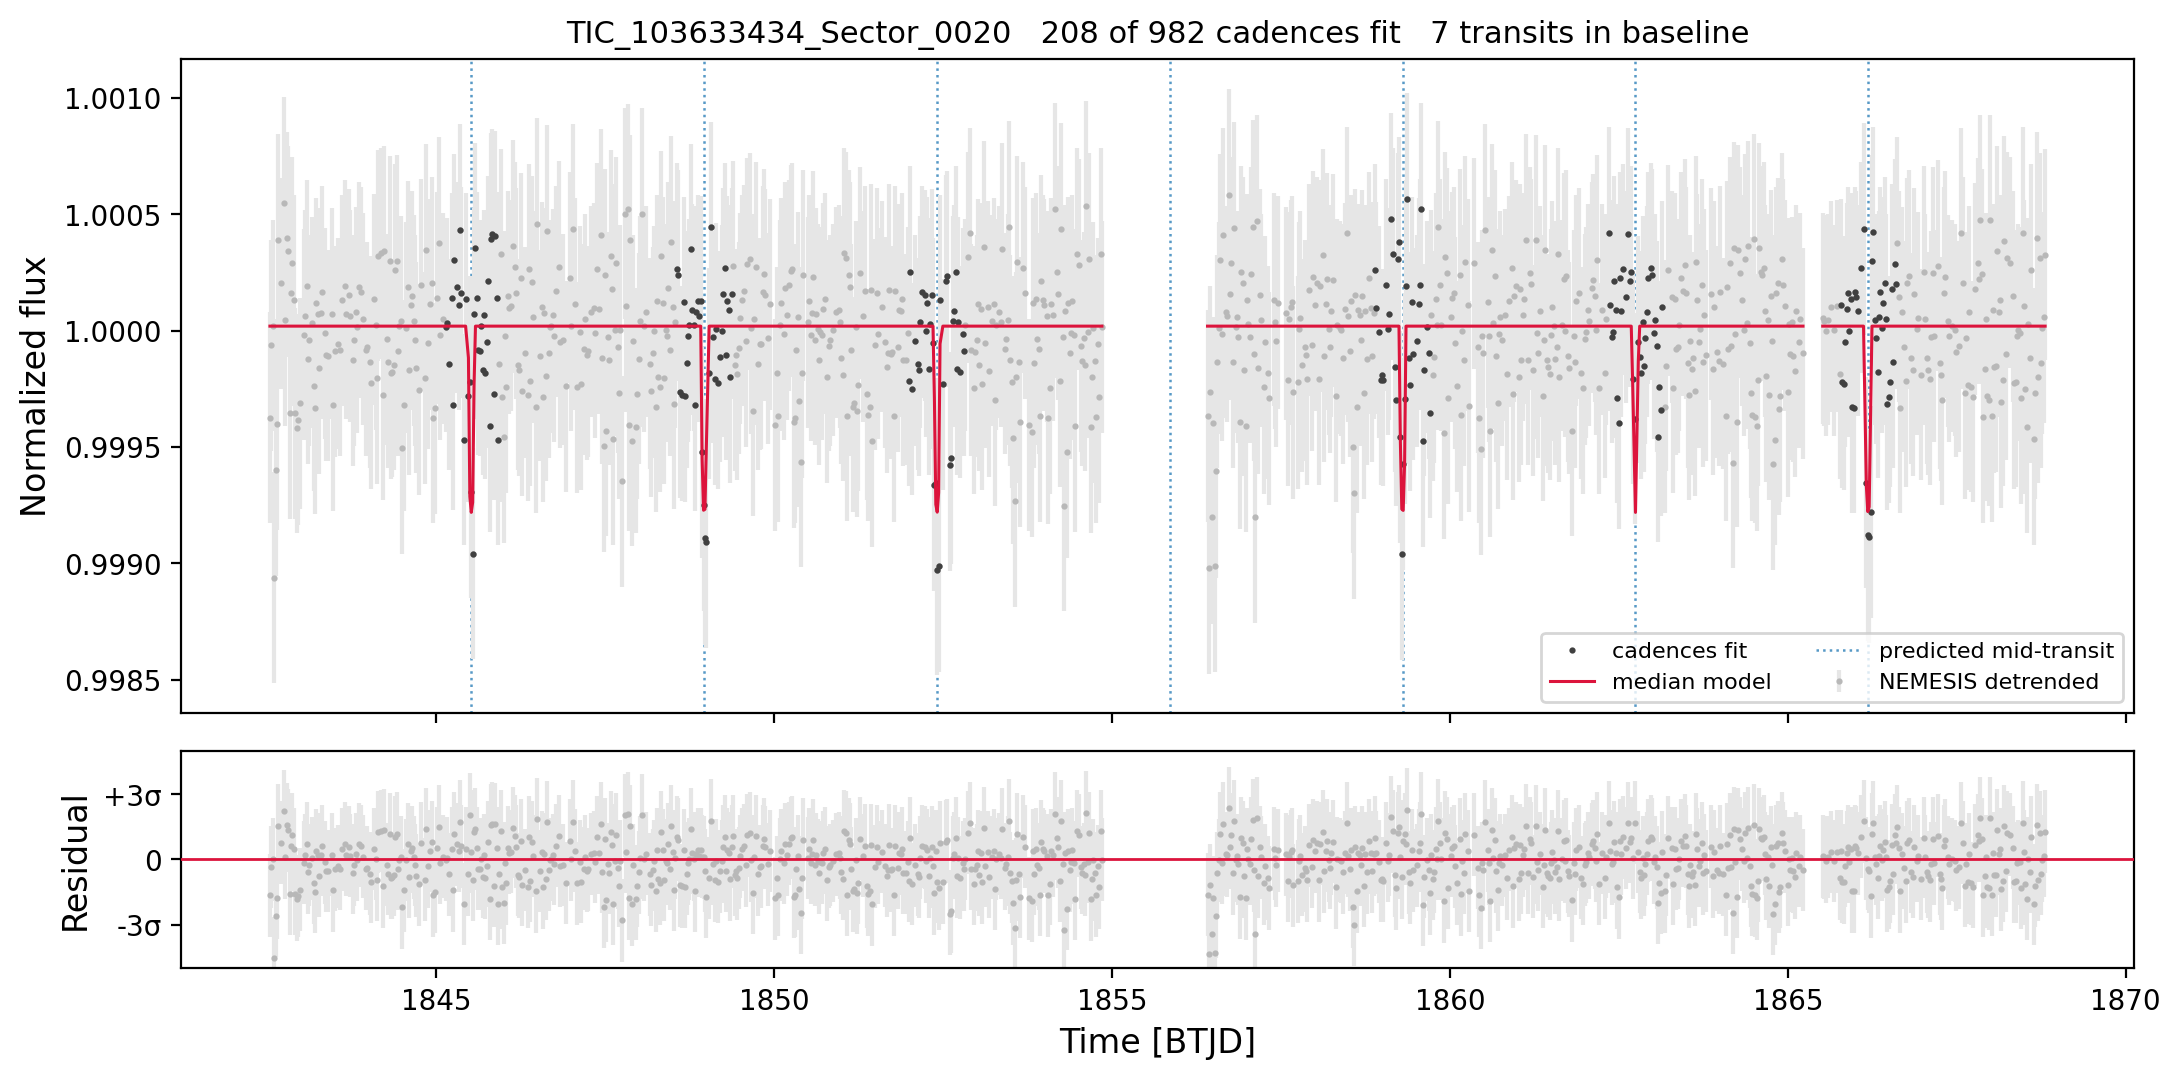

### MCMC convergence diagnostics

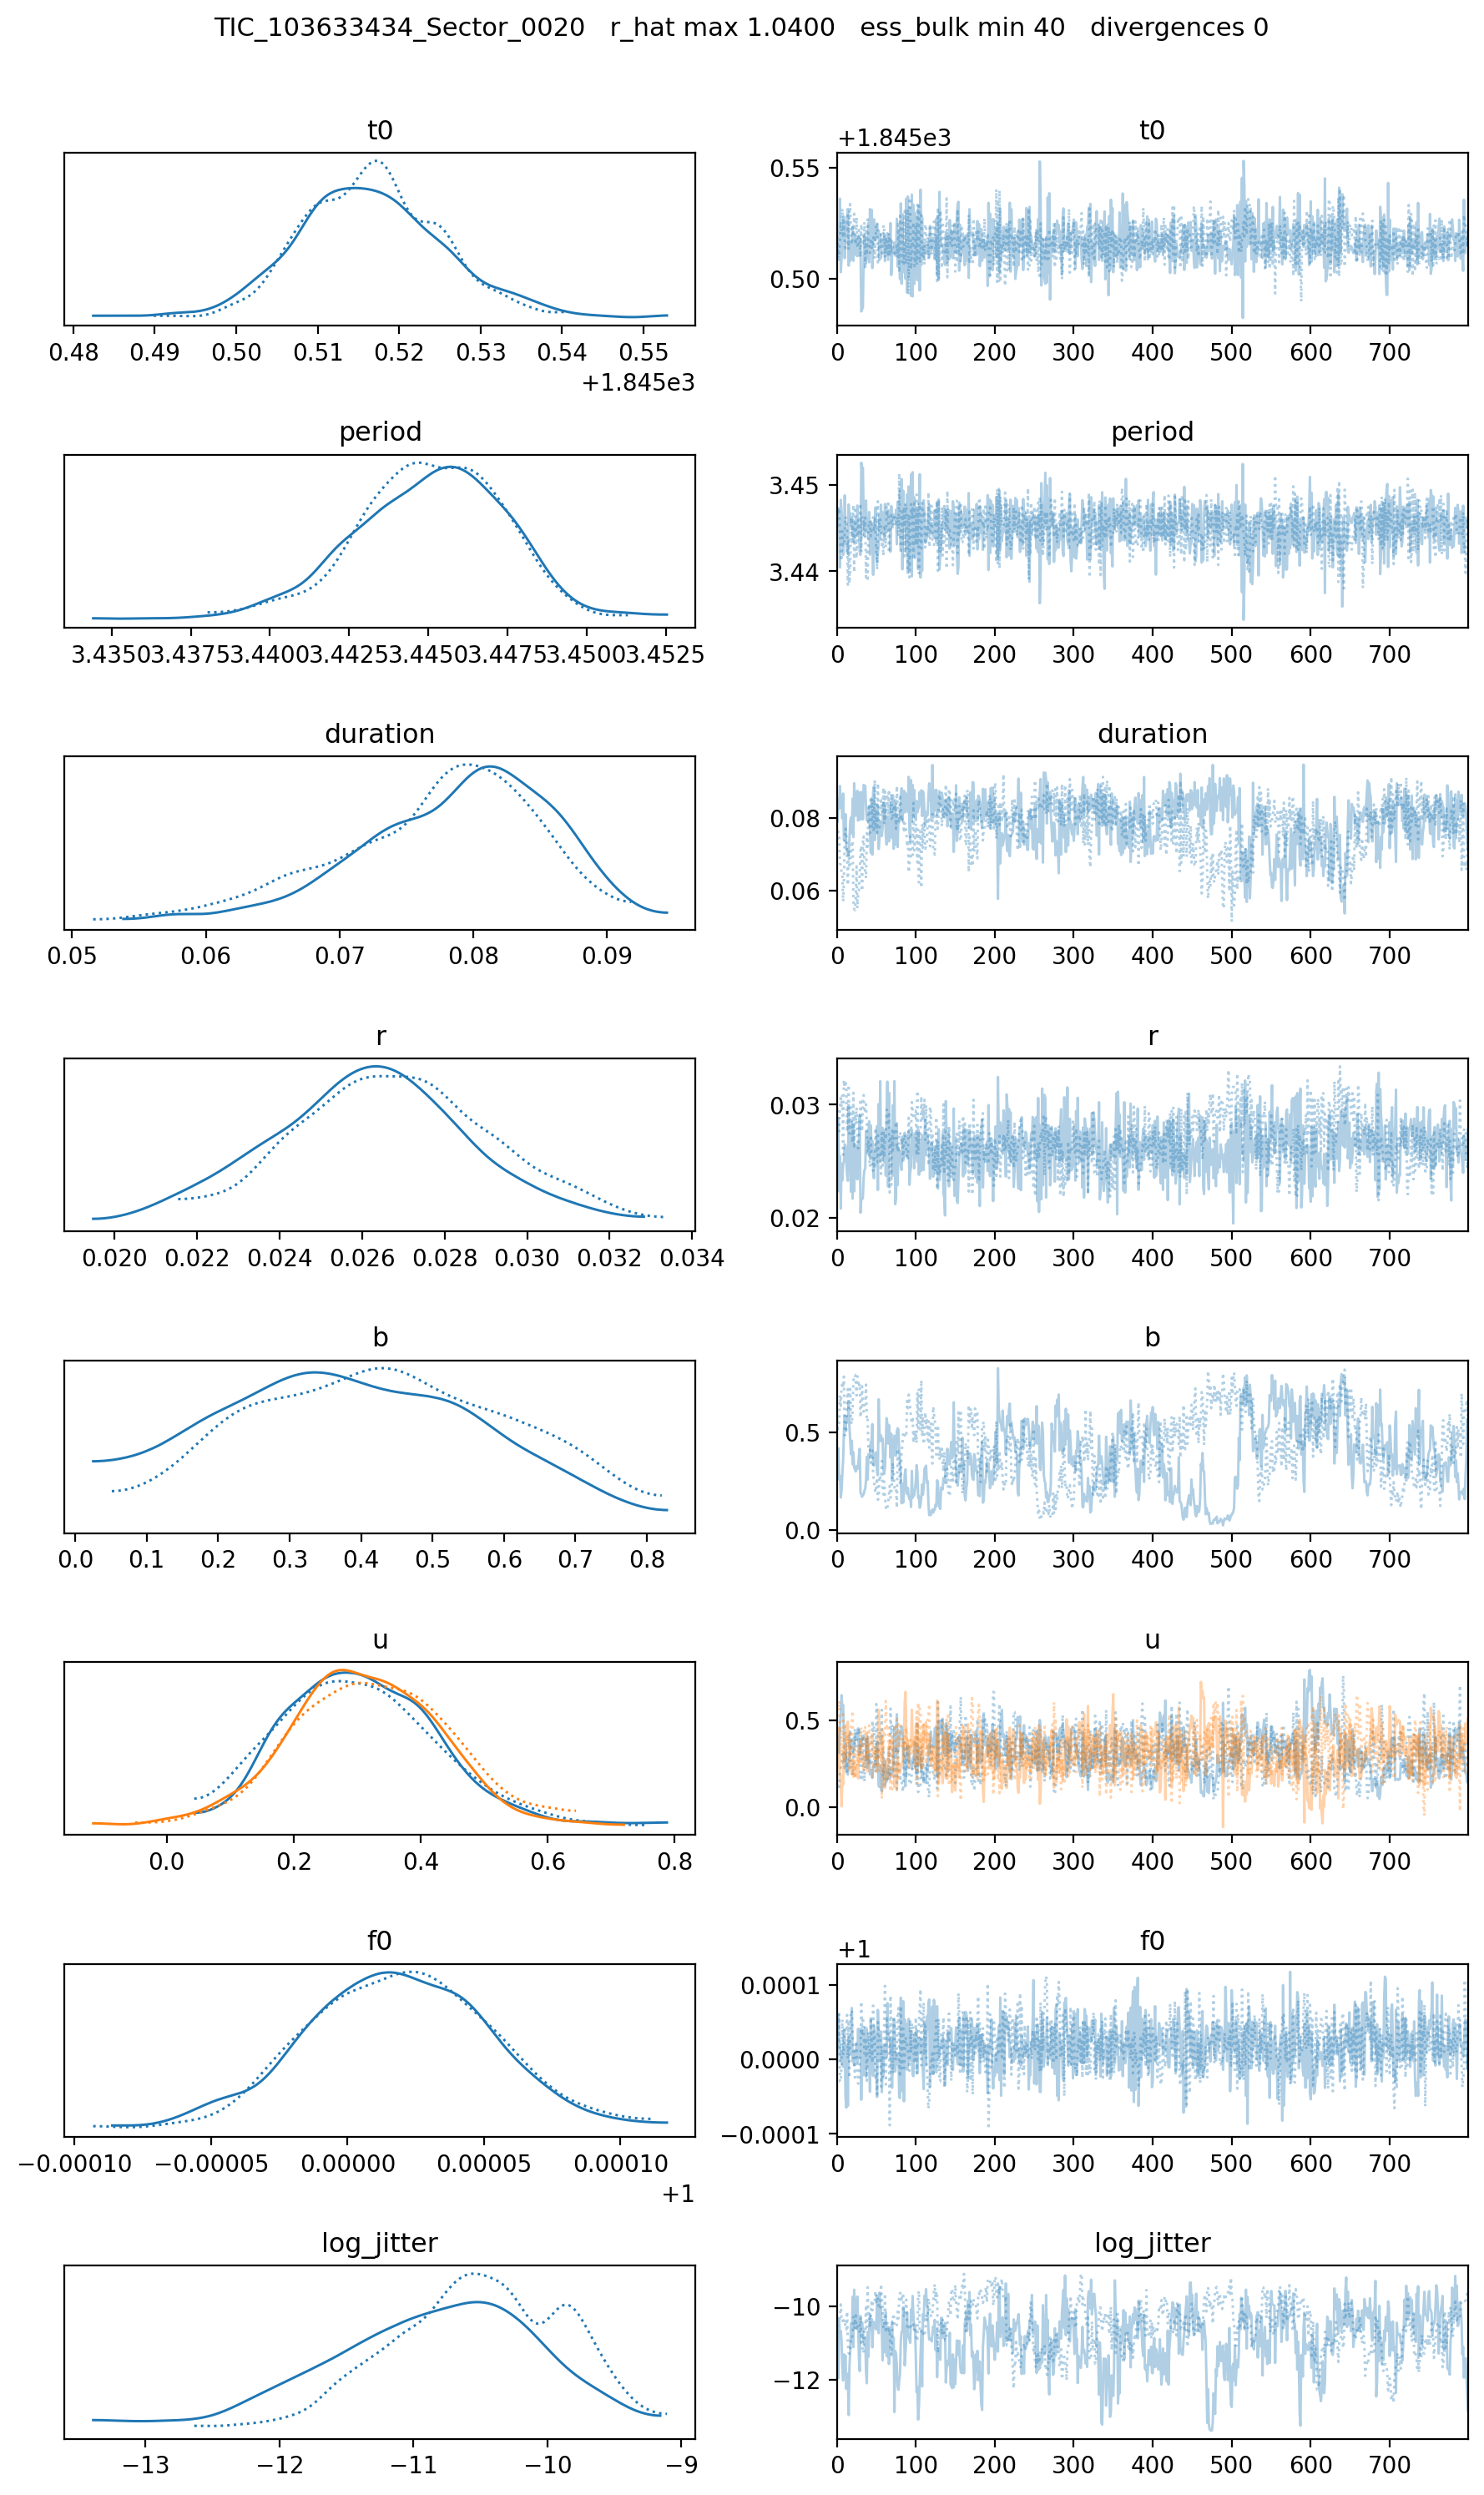

### Posterior parameter distributions

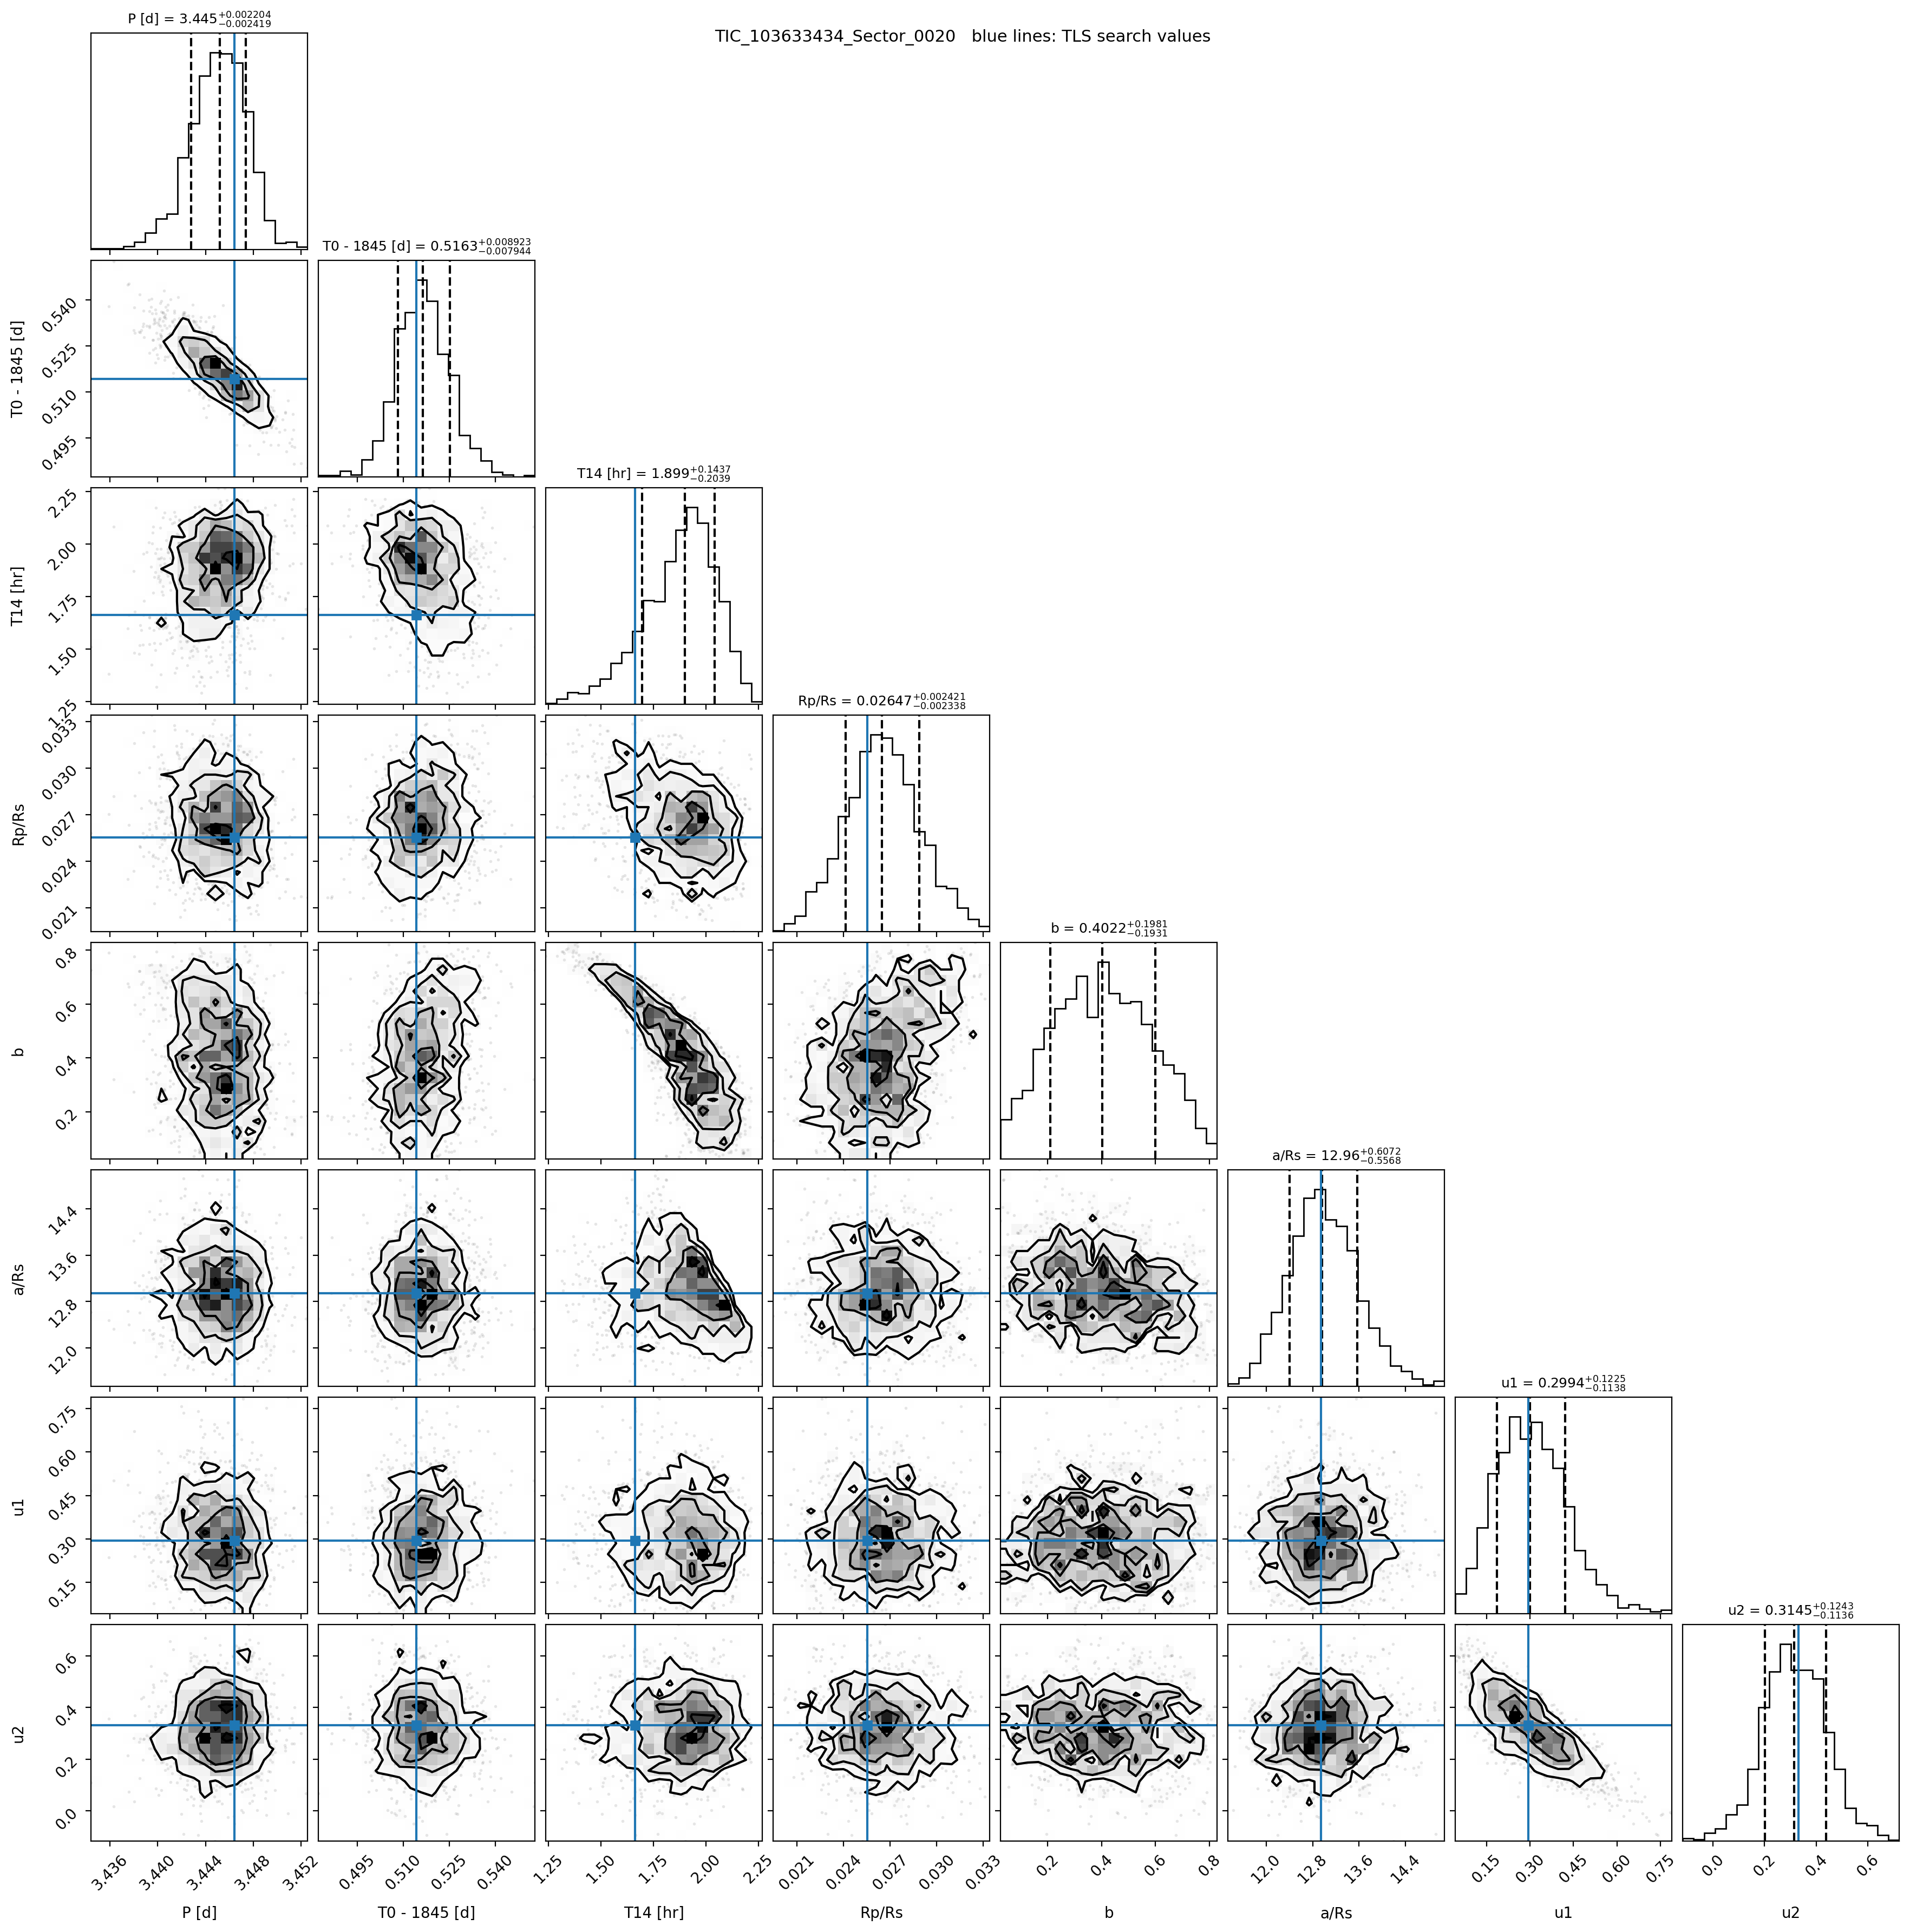

Displayed 4 jaxoplanet diagnostic figures.


In [7]:

from pathlib import Path
from IPython.display import Image, Markdown, display

tic_id = 103633434
sector = 20

plot_dir = (
    Path.home()
    / "nemesis_tutorials"
    / "toi1235_s20"
    / "jaxoplanet"
)

prefix = f"TIC_{tic_id}_Sector_{sector:04d}"

figures = {
    "fit": "Phase-folded transit fit and residuals",
    "timeseries": "Time-series model and residuals",
    "trace": "MCMC convergence diagnostics",
    "corner": "Posterior parameter distributions",
}

n_displayed = 0

for kind, title in figures.items():
    figure_path = plot_dir / f"{prefix}_jaxoplanet_{kind}.png"

    if not figure_path.is_file():
        print(f"Not generated: {figure_path.name}")
        continue

    display(Markdown(f"### {title}"))
    display(Image(filename=str(figure_path), width=950))
    n_displayed += 1

assert n_displayed > 0, f"No jaxoplanet PNGs in {plot_dir}"
print(f"Displayed {n_displayed} jaxoplanet diagnostic figures.")
